[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/01_linear_algebra.ipynb)

# 01 · Linear Algebra for Machine Learning

**Part 0 — Foundations** · Notebook 1 of 27

Machine learning is written in the language of linear algebra. Datasets are matrices, models multiply matrices, PCA and recommender systems are eigenvectors and SVDs, and a transformer is (mostly) a pile of matrix multiplications. This notebook builds the intuition **geometrically**: every matrix is a way of *moving space around*, and once you can see that, most of linear algebra becomes pictures.

**What you'll learn**

1. Data as vectors and matrices
2. Vectors, norms and the dot product (similarity)
3. Matrices as transformations of space
4. Matrix multiplication: three ways to see it
5. Special matrices: identity, diagonal, orthogonal, symmetric
6. Determinant, inverse, rank and null space (and why correlated features break regression)
7. Eigenvectors and eigenvalues
8. Symmetric and positive semi-definite matrices (bowls vs. saddles)
9. The singular value decomposition (SVD)
10. Low-rank approximation: compressing an image
11. Matrix calculus, and solving linear regression exactly

*Course map: CX 4240 Lecture 2 (Linear Algebra Revisit) and HW1 Q1 (PSD matrices); ISYE 4600 HW2 (correlated features, eigenfaces).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")

# Helpers for drawing vectors and transformed grids (used throughout this notebook)
def arrow(ax, v, color, label=None, origin=(0, 0), lw=2.5):
    o = np.asarray(origin, float); v = np.asarray(v, float)
    ax.annotate("", xy=o + v, xytext=o,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=16))
    if label:
        ax.text(*(o + v * 1.08), label, color=color, fontsize=12, weight="bold", ha="center", va="center")

def draw_grid(ax, A=np.eye(2), lim=3.2, n=8, show_basis=True, square=True):
    """Draw the integer grid after it has been transformed by the 2×2 matrix A."""
    A = np.asarray(A, float)
    for k in range(-n, n + 1):
        for seg in (np.array([[k, -n], [k, n]]), np.array([[-n, k], [n, k]])):
            p = seg @ A.T
            ax.plot(p[:, 0], p[:, 1], color=C["blue"], alpha=0.25, lw=1)
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    if square:
        sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]]) @ A.T
        ax.fill(sq[:, 0], sq[:, 1], color=C["yellow"], alpha=0.45)
    if show_basis:
        arrow(ax, A[:, 0], C["orange"], "î")
        arrow(ax, A[:, 1], C["aqua"], "ĵ")
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal")
    ax.grid(False)

print("Drawing helpers ready ✓")

Setup complete ✓
Drawing helpers ready ✓


---
## 1. Data *is* linear algebra

Before any math, here's why this matters. Almost every dataset in ML is stored as a **matrix** $X$ with one **row per example** and one **column per feature**:

$$X = \begin{bmatrix} — & x^{(1)\top} & — \\ — & x^{(2)\top} & — \\ & \vdots & \\ — & x^{(n)\top} & — \end{bmatrix} \in \mathbb{R}^{n \times d}$$

Each row $x^{(i)} \in \mathbb{R}^d$ is a **vector**: one example described by $d$ numbers. Images are matrices too. Here are both:

Feature matrix X (n=4 apartments × d=2 features):
 [[230.   1.]
 [506.   2.]
 [433.   2.]
 [190.   1.]] 



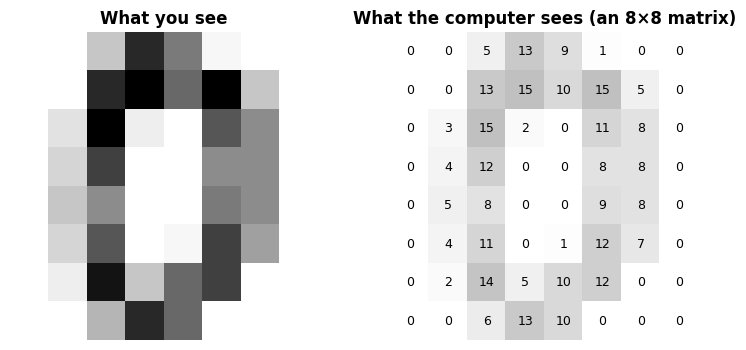

Flattened into a vector of length 64 → one row of a dataset matrix.


In [2]:
import pandas as pd
from sklearn.datasets import load_digits

# (a) The apartment table from CX 4240 Lecture 2, as a matrix
apartments = pd.DataFrame({"area_ft2": [230, 506, 433, 190], "bedrooms": [1, 2, 2, 1], "rent": [900, 1800, 1500, 800]})
X = apartments[["area_ft2", "bedrooms"]].to_numpy(float)
print("Feature matrix X (n=4 apartments × d=2 features):\n", X, "\n")

# (b) An 8×8 handwritten digit: an image is a matrix of pixel intensities
digit = load_digits().images[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.imshow(digit, cmap="Greys")
ax1.set_title("What you see"); ax1.axis("off")
ax2.imshow(digit, cmap="Greys", alpha=0.25)
for (i, j), v in np.ndenumerate(digit):
    ax2.text(j, i, int(v), ha="center", va="center", fontsize=9)
ax2.set_title("What the computer sees (an 8×8 matrix)"); ax2.axis("off")
plt.show()
print("Flattened into a vector of length", digit.size, "→ one row of a dataset matrix.")

And a linear model's predictions for **every** example at once are a single matrix–vector product:

$$\hat{y} = X\theta \qquad \text{(n predictions} = (n\times d) \text{ matrix} \times (d\text{-vector)})$$

That's why GPUs, which are machines for multiplying matrices quickly, made deep learning possible.

---
## 2. Vectors

A vector $v \in \mathbb{R}^d$ is a list of $d$ numbers. You can picture it two ways:
- as a **point** in space (a data point), or
- as an **arrow** from the origin (a direction and a length).

Adding vectors means placing arrows tip to tail. Scaling a vector stretches it (and flips it if the scalar is negative).

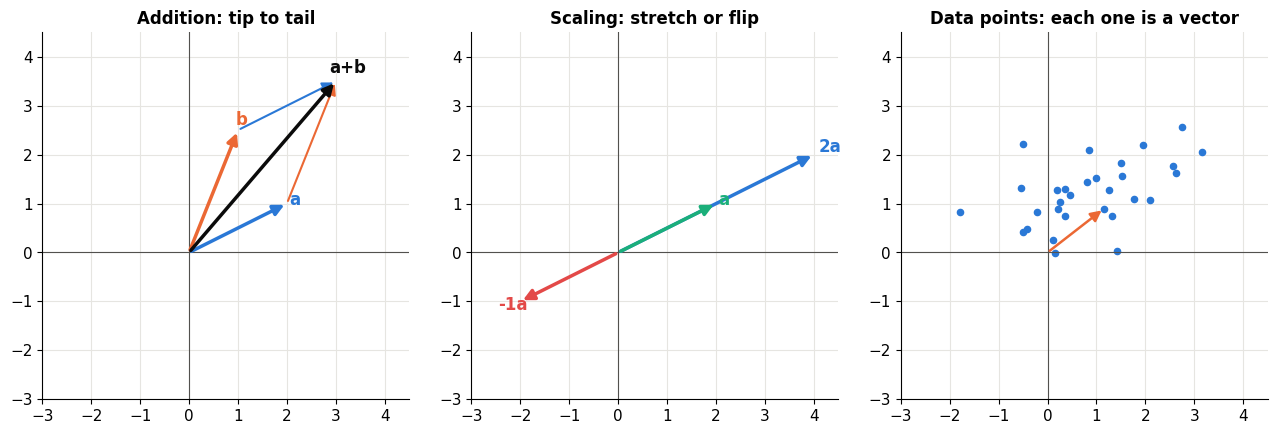

In [3]:
a, b = np.array([2.0, 1.0]), np.array([1.0, 2.5])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax in axes:
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    ax.set(xlim=(-3, 4.5), ylim=(-3, 4.5), aspect="equal")

ax = axes[0]
arrow(ax, a, C["blue"], "a"); arrow(ax, b, C["orange"], "b")
arrow(ax, b, C["orange"], origin=a, lw=1.5); arrow(ax, a, C["blue"], origin=b, lw=1.5)
arrow(ax, a + b, C["ink"], "a+b")
ax.set_title("Addition: tip to tail")

ax = axes[1]
for s, col in [(2, C["blue"]), (1, C["aqua"]), (-1, C["red"])]:
    arrow(ax, s * a, col, f"{s}a" if s != 1 else "a")
ax.set_title("Scaling: stretch or flip")

ax = axes[2]
pts = rng.normal(size=(30, 2)) * [1.2, 0.8] + [1, 1]
ax.scatter(*pts.T, color=C["blue"], s=20)
arrow(ax, pts[0], C["orange"], lw=1.8)
ax.set_title("Data points: each one is a vector")
fig.tight_layout(); plt.show()

### Norms: how long is a vector?

A **norm** $\|v\|$ measures a vector's size. The three you'll meet constantly:

| Norm | Formula | Name | Shows up in |
|---|---|---|---|
| $\ell_2$ | $\sqrt{\sum_i v_i^2}$ | Euclidean length | distances, MSE, Ridge regression |
| $\ell_1$ | $\sum_i \lvert v_i \rvert$ | Manhattan / taxicab | Lasso (sparsity!), robust losses |
| $\ell_\infty$ | $\max_i \lvert v_i \rvert$ | max norm | adversarial robustness |

The general **$\ell_p$ norm** is $\|v\|_p = \left(\sum_i |v_i|^p\right)^{1/p}$. A great way to see a norm is its **unit ball**: all vectors with $\|v\| \le 1$.

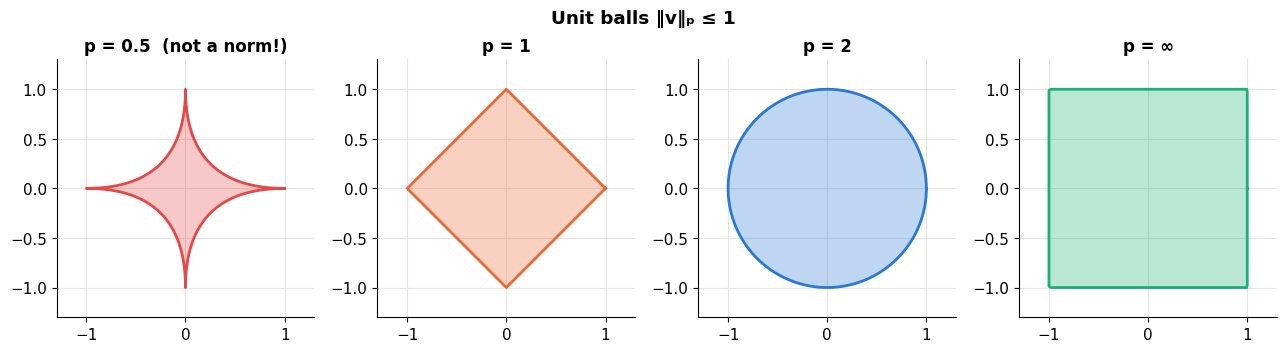

In [4]:
def unit_ball(p, num=400):
    t = np.linspace(0, 2 * np.pi, num)
    if np.isinf(p):
        x, y = np.cos(t), np.sin(t)
        s = np.maximum(np.abs(x), np.abs(y)); return x / s, y / s
    x = np.sign(np.cos(t)) * np.abs(np.cos(t)) ** (2 / p)
    y = np.sign(np.sin(t)) * np.abs(np.sin(t)) ** (2 / p)
    return x, y

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, p, col in zip(axes, [0.5, 1, 2, np.inf], [C["red"], C["orange"], C["blue"], C["aqua"]]):
    ax.fill(*unit_ball(p), color=col, alpha=0.3); ax.plot(*unit_ball(p), color=col)
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal",
           title=f"p = {'∞' if np.isinf(p) else p}" + ("  (not a norm!)" if p < 1 else ""))
fig.suptitle("Unit balls ‖v‖ₚ ≤ 1", weight="bold"); fig.tight_layout(); plt.show()

🎚️ **Drag $p$** and watch the unit ball morph from a spiky star ($p<1$), to a diamond ($p=1$), a circle ($p=2$), and a square ($p\to\infty$).

In [5]:
def plot_ball(p=2.0):
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    x, y = unit_ball(p)
    ax.fill(x, y, color=C["blue"], alpha=0.25); ax.plot(x, y, color=C["blue"])
    ax.plot(*unit_ball(2), color=C["muted"], ls="--", lw=1, label="p = 2 for reference")
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", title=f"‖v‖_{p:.2f} ≤ 1")
    ax.legend(loc="lower left", fontsize=8); plt.show()

interact(plot_ball, p=FloatSlider(value=2, min=0.3, max=10, step=0.1, description="p"));

> 🤔 **Question: Why does it matter that the $\ell_1$ ball has sharp corners?**
>
> This is the secret behind **Lasso** (notebook 07). When you minimize a loss subject to $\|\theta\|_1 \le t$, the loss contours usually first touch the diamond **at a corner**, and at a corner some coordinates are exactly zero. So $\ell_1$ regularization automatically sets useless feature weights to zero (feature selection), while $\ell_2$ (the round ball) only shrinks them. Keep this picture in mind.

> 🤔 **Question: Why is $p < 1$ "not a norm"?**
>
> A norm must satisfy the triangle inequality $\|a+b\| \le \|a\|+\|b\|$. For $p<1$ that fails, which you can see in the picture: the ball isn't **convex** (it caves inwards), so the straight line between two points in the ball leaves the ball.

---
## 3. The dot product: measuring similarity

The **dot product** has an algebraic definition and a geometric meaning, and the fact that they agree is one of the most useful facts in ML:

$$a \cdot b = a^\top b = \sum_{i} a_i b_i \;=\; \|a\|\,\|b\|\cos\theta$$

where $\theta$ is the angle between the vectors. So:
- **positive** → pointing roughly the same way,
- **zero** → perpendicular (**orthogonal**),
- **negative** → pointing in opposite directions.

Dividing out the lengths gives **cosine similarity**, $\cos\theta = \frac{a^\top b}{\|a\|\|b\|} \in [-1, 1]$, which only cares about direction.

The dot product also gives **projection**: the shadow of $b$ onto the direction of $a$ has length $\frac{a^\top b}{\|a\|}$.

🎚️ **Rotate $b$** and watch the dot product, the cosine and the projection (the green shadow).

In [6]:
def plot_dot(angle_deg=60, length_b=2.0):
    a = np.array([2.5, 0.8])
    ang = np.deg2rad(angle_deg) + np.arctan2(a[1], a[0])
    b = length_b * np.array([np.cos(ang), np.sin(ang)])
    proj = (a @ b) / (a @ a) * a
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    ax.plot([b[0], proj[0]], [b[1], proj[1]], ls=":", color=C["muted"])
    ax.plot([0, proj[0]], [0, proj[1]], color=C["aqua"], lw=6, alpha=0.6, solid_capstyle="butt", label="projection of b on a")
    arrow(ax, a, C["blue"], "a"); arrow(ax, b, C["orange"], "b")
    ax.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect="equal")
    ax.set_title(f"a·b = {a @ b:+.2f}    cos θ = {a @ b / np.linalg.norm(a) / np.linalg.norm(b):+.2f}")
    ax.legend(loc="lower left", fontsize=9); plt.show()

interact(plot_dot,
         angle_deg=IntSlider(value=60, min=0, max=360, step=5, description="angle (°)"),
         length_b=FloatSlider(value=2, min=0.2, max=3, step=0.1, description="‖b‖"));

### Cosine similarity in action: which users have similar taste?

Here are 4 users' ratings (1–5) of 5 movies. Each user is a vector; cosine similarity tells us whose tastes point the same way. This is the core of **collaborative filtering** (notebook 17), and the same operation, a matrix of dot products, is the heart of **attention** in transformers (notebook 25).

,Avengers,John Wick,Notebook,Titanic,Inception
Ana,5,5,1,2,4
Ben,4,5,2,1,5
Cara,1,2,5,5,2
Dev,2,1,4,5,1


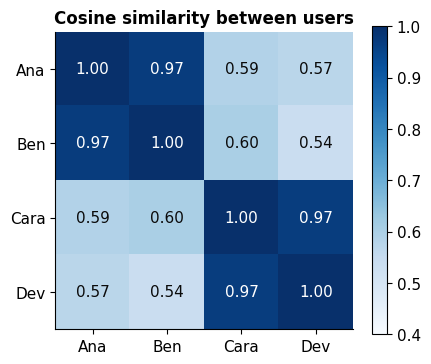

In [7]:
movies = ["Avengers", "John Wick", "Notebook", "Titanic", "Inception"]
R = pd.DataFrame([[5, 5, 1, 2, 4],
                  [4, 5, 2, 1, 5],
                  [1, 2, 5, 5, 2],
                  [2, 1, 4, 5, 1]], columns=movies, index=["Ana", "Ben", "Cara", "Dev"])
display(R)

U = R.to_numpy(float)
norms = np.linalg.norm(U, axis=1, keepdims=True)
cos_sim = (U @ U.T) / (norms @ norms.T)        # all pairwise dot products in ONE matrix multiply

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cos_sim, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(4), R.index); ax.set_yticks(range(4), R.index); ax.grid(False)
for (i, j), v in np.ndenumerate(cos_sim):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.8 else C["ink"])
ax.set_title("Cosine similarity between users"); plt.colorbar(im, ax=ax); plt.show()

Ana and Ben (action fans) are 0.97 similar; Cara and Dev (romance fans) are too. Notice `U @ U.T` computed **all 16 dot products at once**: a matrix product is just a table of dot products.

> 🤔 **Question: All ratings are positive, so every cosine is positive. Isn't "0.6" pretty similar?**
>
> Good catch. With all-positive data every vector lives in the same quadrant, so cosines are inflated. The fix is to **center** each user's ratings (subtract their average) first. That's exactly **Pearson correlation**, which ISYE 4600 recommends for correcting users who rate everything high or low. Try it: replace `U` with `U - U.mean(axis=1, keepdims=True)`.

---
## 4. Matrices are transformations of space

Here is the single most important idea in this notebook (popularized by 3Blue1Brown):

> **A matrix is a function that moves every point in space.** The columns of the matrix tell you where the basis vectors $\hat\imath = (1,0)$ and $\hat\jmath = (0,1)$ land.

Why? Any vector is a combination of the basis vectors, $v = v_1 \hat\imath + v_2\hat\jmath$, and a matrix acts *linearly*, so

$$Av = v_1 (A\hat\imath) + v_2 (A\hat\jmath) = v_1 \cdot (\text{column 1}) + v_2 \cdot (\text{column 2}).$$

Lines stay lines, the origin stays put, and grid lines stay parallel and evenly spaced. The yellow unit square shows how areas change.

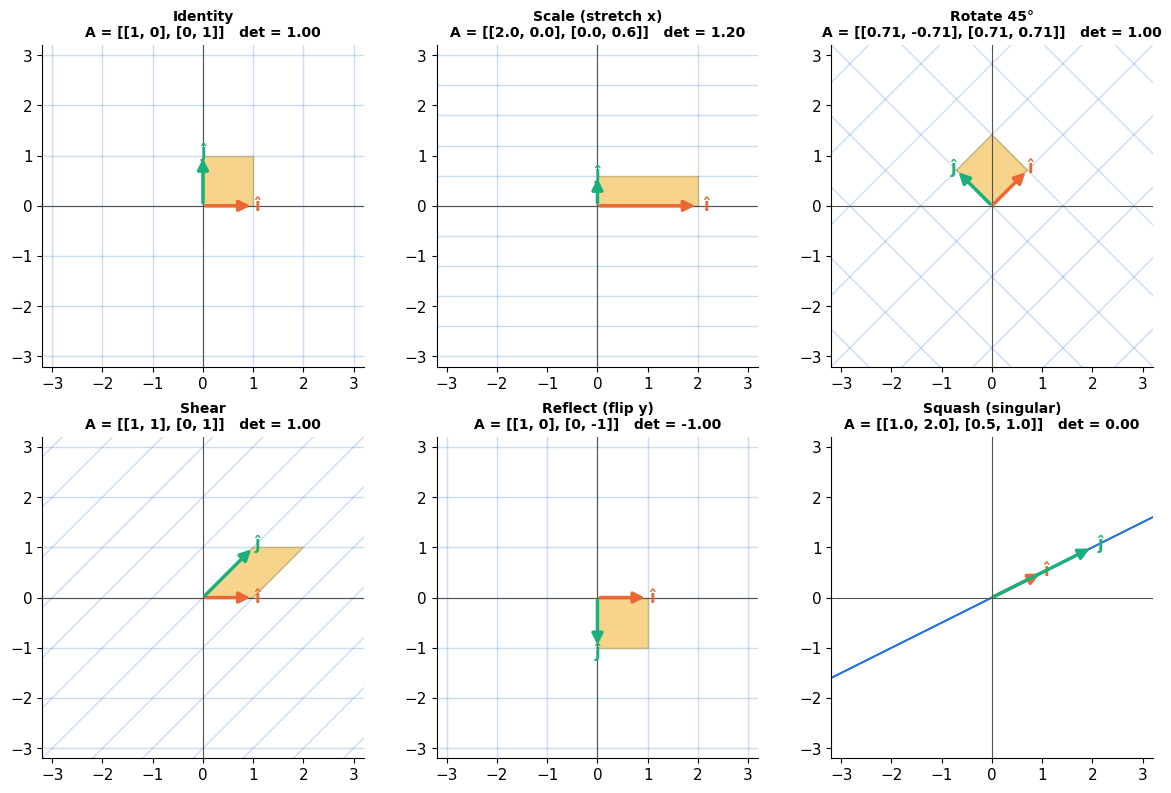

In [8]:
examples = {
    "Identity":            [[1, 0], [0, 1]],
    "Scale (stretch x)":   [[2, 0], [0, 0.6]],
    "Rotate 45°":          [[np.cos(np.pi/4), -np.sin(np.pi/4)], [np.sin(np.pi/4), np.cos(np.pi/4)]],
    "Shear":               [[1, 1], [0, 1]],
    "Reflect (flip y)":    [[1, 0], [0, -1]],
    "Squash (singular)":   [[1, 2], [0.5, 1]],
}
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (name, A) in zip(axes.flat, examples.items()):
    draw_grid(ax, A)
    ax.set_title(f"{name}\nA = {np.round(A, 2).tolist()}   det = {np.linalg.det(A):.2f}", fontsize=10)
fig.tight_layout(); plt.show()

### 🎬 Watch a matrix move space

The animation smoothly morphs the grid from the identity into $A = \begin{bmatrix} 1 & 1 \\ 0.5 & 1.5\end{bmatrix}$. Watch the orange $\hat\imath$ arrow land on column 1 $(1, 0.5)$ and the aqua $\hat\jmath$ land on column 2 $(1, 1.5)$.

In [9]:
A_demo = np.array([[1, 1], [0.5, 1.5]])
fig, ax = plt.subplots(figsize=(5, 5), dpi=80)

def frame(k):
    t = min(k / 30, 1)
    ax.cla()
    draw_grid(ax, (1 - t) * np.eye(2) + t * A_demo)
    ax.set_title(f"t = {t:.2f}")

show_anim(animation.FuncAnimation(fig, frame, frames=40, interval=80))

🎚️ **Build your own matrix.** Set the four entries and see the transformation. Things to try:
- `a=2, d=2`: uniform scaling (area ×4, so det = 4).
- `a=0, b=-1, c=1, d=0`: rotation by 90°.
- `a=1, b=2, c=0.5, d=1`: everything collapses onto a line (det = 0).
- `a=-1, d=1`: a mirror flip (det < 0 means orientation flips; note î and ĵ swap their clockwise order).

In [10]:
def plot_transform(a=1.0, b=0.5, c=0.0, d=1.0):
    A = np.array([[a, b], [c, d]])
    fig, ax = plt.subplots(figsize=(5, 5))
    draw_grid(ax, A)
    ax.set_title(f"A = [[{a}, {b}], [{c}, {d}]]    det(A) = {np.linalg.det(A):.2f}")
    plt.show()

s = dict(min=-2, max=2, step=0.1)
interact(plot_transform, a=FloatSlider(value=1, **s), b=FloatSlider(value=0.5, **s),
         c=FloatSlider(value=0, **s), d=FloatSlider(value=1, **s));

> 🤔 **Question: A neural network layer computes $\sigma(Wx + b)$. Where does that fit in this picture?**
>
> $Wx$ is exactly this: a linear transformation of space. $+b$ shifts it (so the origin can move), and $\sigma$ (a nonlinearity like ReLU) bends it. A deep network alternates "transform linearly, then bend", and with enough layers it can untangle very complicated data. Notebook 19 shows this happening, layer by layer.

---
## 5. Matrix multiplication: three ways to see it

For $A \in \mathbb{R}^{m\times k}$ and $B \in \mathbb{R}^{k\times n}$, the product $AB \in \mathbb{R}^{m \times n}$ can be read three ways:

1. **Table of dot products:** $(AB)_{ij} = (\text{row } i \text{ of } A) \cdot (\text{column } j \text{ of } B)$.
2. **Combinations of columns:** each column of $AB$ is a combination of $A$'s columns, weighted by a column of $B$.
3. **Composition of transformations:** $ABx = A(Bx)$, so $AB$ means "do $B$ first, then $A$" (read right to left).

The **shape rule**: inner dimensions must match, $(m \times \mathbf{k})(\mathbf{k} \times n) \to (m \times n)$.

Let's implement view 1 with plain loops and compare with NumPy:

In [11]:
import time

def matmul_loops(A, B):
    m, k = A.shape; k2, n = B.shape
    assert k == k2, f"shape mismatch: {A.shape} @ {B.shape}"
    out = np.zeros((m, n))
    for i in range(m):
        for j in range(n):
            out[i, j] = sum(A[i, p] * B[p, j] for p in range(k))   # row i · column j
    return out

A = rng.normal(size=(120, 80)); B = rng.normal(size=(80, 100))
t0 = time.perf_counter(); M1 = matmul_loops(A, B); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); M2 = A @ B;               t_np = time.perf_counter() - t0
print(f"Same answer: {np.allclose(M1, M2)}")
print(f"Python loops: {t_loop*1000:8.1f} ms")
print(f"NumPy  (@)  : {t_np*1000:8.3f} ms   → {t_loop/t_np:,.0f}× faster")

Same answer: True
Python loops:    262.9 ms
NumPy  (@)  :    0.152 ms   → 1,724× faster


NumPy calls optimized, parallel, cache-aware routines (BLAS). GPUs push the same idea further, with thousands of cores multiplying in parallel. **Lesson for all future notebooks: never loop over data in Python when a matrix operation will do.**

### Order matters: $AB \neq BA$

Because $AB$ means "apply $B$, then $A$", swapping the order usually gives a different transformation. Watch an asymmetric "F" shape:

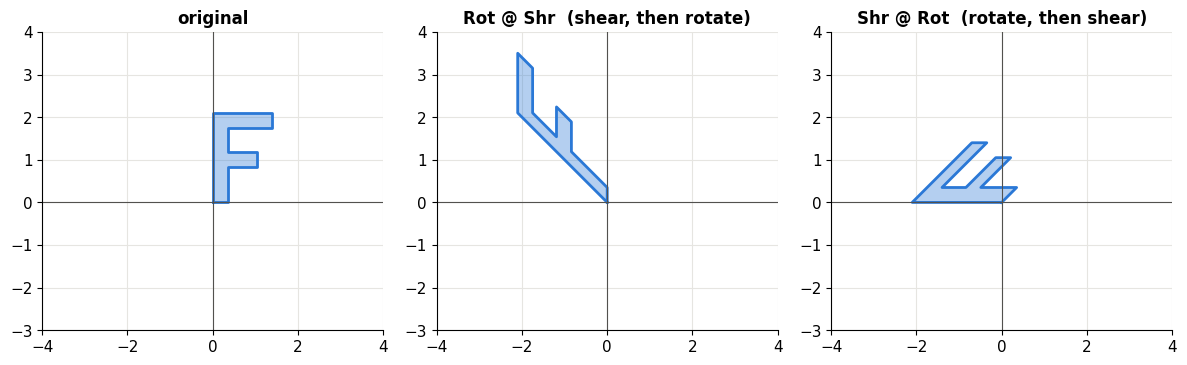

In [12]:
F = np.array([[0, 0], [0, 3], [2, 3], [2, 2.5], [0.5, 2.5], [0.5, 1.7], [1.5, 1.7],
              [1.5, 1.2], [0.5, 1.2], [0.5, 0], [0, 0]]) * 0.7
Rot = np.array([[0, -1], [1, 0]])        # rotate 90°
Shr = np.array([[1, 1], [0, 1]])         # shear

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (M, name) in zip(axes, [(np.eye(2), "original"), (Rot @ Shr, "Rot @ Shr  (shear, then rotate)"),
                                (Shr @ Rot, "Shr @ Rot  (rotate, then shear)")]):
    P = F @ M.T
    ax.fill(*P.T, color=C["blue"], alpha=0.35); ax.plot(*P.T, color=C["blue"])
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    ax.set(xlim=(-4, 4), ylim=(-3, 4), aspect="equal", title=name)
fig.tight_layout(); plt.show()

---
## 6. Special matrices you'll see everywhere

| Matrix | Definition | Geometric meaning | Where in ML |
|---|---|---|---|
| **Identity** $I$ | 1s on diagonal, 0 elsewhere | does nothing: $Ix = x$ | residual connections ($x + f(x)$) |
| **Diagonal** $D$ | only diagonal entries | stretches each axis independently | feature scaling, eigenvalues $\Lambda$ |
| **Orthogonal** $Q$ | $Q^\top Q = I$ | rotation or reflection: preserves lengths and angles | PCA directions, SVD's $U, V$ |
| **Symmetric** $S$ | $S = S^\top$ | stretches along perpendicular axes | covariance matrices, Hessians, $X^\top X$ |

The **trace** $\text{tr}(A) = \sum_i A_{ii}$ (sum of the diagonal) also appears often. We'll see shortly that it equals the sum of the eigenvalues.

In [13]:
theta = np.deg2rad(30)
Q = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
v = np.array([3.0, 4.0])
print("Orthogonal check  QᵀQ =\n", np.round(Q.T @ Q, 10))
print(f"‖v‖ = {np.linalg.norm(v):.4f}   ‖Qv‖ = {np.linalg.norm(Q @ v):.4f}   ← length preserved")
print(f"Q⁻¹ equals Qᵀ: {np.allclose(np.linalg.inv(Q), Q.T)}   ← inverting a rotation is free")

S = rng.normal(size=(4, 4)); S = S + S.T
print(f"\nSymmetric S: trace = {np.trace(S):.4f}, sum of eigenvalues = {np.linalg.eigvalsh(S).sum():.4f}")

Orthogonal check  QᵀQ =
 [[1. 0.]
 [0. 1.]]
‖v‖ = 5.0000   ‖Qv‖ = 5.0000   ← length preserved
Q⁻¹ equals Qᵀ: True   ← inverting a rotation is free

Symmetric S: trace = 3.5037, sum of eigenvalues = 3.5037


---
## 7. Determinant, inverse, rank and null space

**Determinant** $\det(A)$: the factor by which $A$ scales **areas** (volumes in higher dimensions). You saw it on the yellow square: rotation gives 1, scaling by 2 in both directions gives 4, and the singular "squash" matrix gives **0** because it flattens the plane onto a line.

**Inverse** $A^{-1}$: the transformation that undoes $A$, so $A^{-1}A = I$. It exists **if and only if $\det(A) \ne 0$**. Once space has been squashed onto a line, many points have landed in the same place and there's no way to tell them apart, so nothing can undo it.

**Rank**: the number of dimensions of the output (the **column space**). Full rank = no squashing.

**Null space**: all the vectors that get squashed to exactly $0$. If it contains anything besides $0$, information is lost.

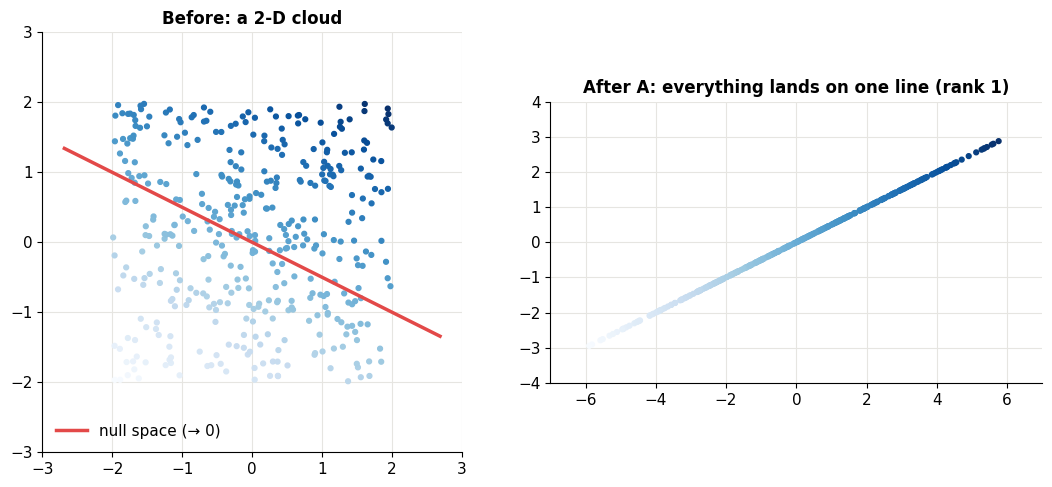

rank = 1   det = 0.0
A @ null direction = [0. 0.]


In [14]:
A_sing = np.array([[1, 2], [0.5, 1]])          # column 2 = 2 × column 1 → rank 1
pts = rng.uniform(-2, 2, size=(400, 2))
out = pts @ A_sing.T

null_dir = np.array([2, -1]) / np.sqrt(5)       # A_sing @ [2, -1] = [0, 0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
ax1.scatter(*pts.T, c=pts[:, 0] + 2 * pts[:, 1], cmap="Blues", s=12)
ax1.plot(*np.outer([-3, 3], null_dir).T, color=C["red"], lw=2.5, label="null space (→ 0)")
ax1.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title="Before: a 2-D cloud"); ax1.legend(loc="lower left")
ax2.scatter(*out.T, c=pts[:, 0] + 2 * pts[:, 1], cmap="Blues", s=12)
ax2.set(xlim=(-7, 7), ylim=(-4, 4), aspect="equal", title="After A: everything lands on one line (rank 1)")
fig.tight_layout(); plt.show()

print("rank =", np.linalg.matrix_rank(A_sing), "  det =", np.linalg.det(A_sing))
print("A @ null direction =", A_sing @ null_dir)

Points with the same color land on the same spot, so the transformation can't be undone. Every point along a red-line direction collapses together.

### Why this matters: correlated features break linear regression

This is exactly ISYE 4600 HW2's motivating problem. Suppose two features are perfectly correlated, say "area in ft²" and "area in m²", or bathrooms $x_1 = 1.5\,x_2$. Then one column of $X$ is a multiple of another, $X$ is rank-deficient, and the matrix $X^\top X$ that linear regression must invert is **singular**. Infinitely many $\theta$'s fit equally well.

In [15]:
n = 50
area_ft2 = rng.uniform(300, 1400, n)
X_bad = np.column_stack([np.ones(n), area_ft2, area_ft2 * 0.0929])      # ft² and m²: perfectly correlated
X_ok  = np.column_stack([np.ones(n), area_ft2, rng.integers(1, 4, n)])   # area and bedrooms

for name, Xm in [("area_ft2 + area_m2", X_bad), ("area + bedrooms", X_ok)]:
    G = Xm.T @ Xm
    print(f"{name:20s} rank(X) = {np.linalg.matrix_rank(Xm)} of {Xm.shape[1]}   "
          f"condition number of XᵀX = {np.linalg.cond(G):.2e}")

area_ft2 + area_m2   rank(X) = 2 of 3   condition number of XᵀX = 3.99e+17
area + bedrooms      rank(X) = 3 of 3   condition number of XᵀX = 9.66e+06


A **condition number** around $10^{16}$ or more means "numerically singular": inverting it amplifies rounding errors enormously. The cures are dropping redundant features, **PCA** (notebook 16), or **Ridge regression** (notebook 07), which adds $\lambda I$ to $X^\top X$ to make it invertible.

> 🤔 **Question: Should I use `np.linalg.inv(A) @ b` to solve $Ax = b$?**
>
> Almost never. `np.linalg.solve(A, b)` is faster and more numerically accurate because it never forms the inverse explicitly (it uses an LU factorization). For least squares, `np.linalg.lstsq` is even more robust, and it works when $X^\top X$ is singular too.

---
## 8. Eigenvectors and eigenvalues

Most vectors get knocked off their direction when you apply a matrix. But some special directions only get **stretched**, never rotated. Those are the **eigenvectors**:

$$A v = \lambda v$$

- $v$ is an **eigenvector** (a direction that stays on its own line),
- $\lambda$ is its **eigenvalue** (the stretch factor; negative means it flips).

### 🎬 Watch the eigenvectors

Below, 24 gray vectors around the unit circle get transformed by $A = \begin{bmatrix}2 & 1\\1 & 2\end{bmatrix}$. Almost all of them rotate, but the **red** and **orange** ones stay on their lines: those are the eigenvectors, stretched by $\lambda = 3$ and $\lambda = 1$.

In [16]:
A_eig = np.array([[2.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A_eig)                       # eigh: for symmetric matrices
angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
circle = np.column_stack([np.cos(angles), np.sin(angles)])

fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=80)
def frame(k):
    t = min(k / 30, 1)
    M = (1 - t) * np.eye(2) + t * A_eig
    ax.cla()
    for d in V.T:
        ax.plot(*np.outer([-4, 4], d).T, color=C["light"], lw=1, ls="--")
    for v in circle:
        arrow(ax, M @ v, C["muted"], lw=1.2)
    arrow(ax, M @ V[:, 1], C["red"], f"λ={lam[1]:.0f}")
    arrow(ax, M @ V[:, 0], C["orange"], f"λ={lam[0]:.0f}")
    ax.set(xlim=(-3.6, 3.6), ylim=(-3.6, 3.6), aspect="equal", title=f"t = {t:.2f}")
    ax.grid(False)

show_anim(animation.FuncAnimation(fig, frame, frames=40, interval=80))

### Finding eigenvalues by hand

$Av = \lambda v \iff (A - \lambda I)v = 0$. For a nonzero $v$ to be squashed to zero, $A - \lambda I$ must be singular:

$$\det(A - \lambda I) = 0 \quad \text{(the characteristic equation)}$$

For our matrix: $\det\begin{bmatrix}2-\lambda & 1\\1 & 2-\lambda\end{bmatrix} = (2-\lambda)^2 - 1 = 0 \implies \lambda = 1 \text{ or } 3$.

Plug $\lambda=3$ back in: $\begin{bmatrix}-1 & 1\\1 & -1\end{bmatrix}v = 0 \implies v \propto (1, 1)$. And $\lambda = 1$ gives $v \propto (1,-1)$.

In [17]:
print("NumPy eigenvalues :", lam)
print("NumPy eigenvectors (columns):\n", np.round(V, 4))
for i in range(2):
    print(f"check A v{i} = λ v{i}:", np.allclose(A_eig @ V[:, i], lam[i] * V[:, i]))

NumPy eigenvalues : [1. 3.]
NumPy eigenvectors (columns):
 [[-0.7071  0.7071]
 [ 0.7071  0.7071]]
check A v0 = λ v0: True
check A v1 = λ v1: True


🎚️ **Explore any 2×2 matrix.** The dashed lines are its eigen-directions (when they're real). Try:
- a **rotation** (`a=0, b=-1, c=1, d=0`): no real eigenvectors, since every direction rotates.
- a **shear** (`a=1, b=1, c=0, d=1`): only *one* eigen-direction.
- a symmetric matrix (`b = c`): the eigen-directions are always **perpendicular**.

In [18]:
def plot_eigen(a=2.0, b=1.0, c=1.0, d=2.0):
    A = np.array([[a, b], [c, d]])
    fig, ax = plt.subplots(figsize=(5, 5))
    for v in circle:
        ax.plot([v[0], (A @ v)[0]], [v[1], (A @ v)[1]], color=C["light"], lw=0.8)
        arrow(ax, A @ v, C["muted"], lw=1)
    lam, V = np.linalg.eig(A)
    txt = []
    for i, col in enumerate([C["red"], C["orange"]]):
        if abs(lam[i].imag) < 1e-9:
            vv = V[:, i].real
            ax.plot(*np.outer([-5, 5], vv).T, color=col, ls="--", lw=1.5)
            arrow(ax, lam[i].real * vv, col)
            txt.append(f"λ{i+1}={lam[i].real:.2f}")
        else:
            txt.append(f"λ{i+1}={lam[i]:.2f} (complex)")
    ax.set(xlim=(-4, 4), ylim=(-4, 4), aspect="equal", title="   ".join(txt)); ax.grid(False)
    plt.show()

s = dict(min=-2, max=3, step=0.1)
interact(plot_eigen, a=FloatSlider(value=2, **s), b=FloatSlider(value=1, **s),
         c=FloatSlider(value=1, **s), d=FloatSlider(value=2, **s));

### Eigendecomposition: rotate, stretch, rotate back

For a **symmetric** matrix, the eigenvectors are perpendicular and we can stack them into an orthogonal matrix $Q$:

$$A = Q \Lambda Q^\top$$

Read right to left: rotate into the eigen-axes ($Q^\top$), stretch each axis by its eigenvalue ($\Lambda$), rotate back ($Q$). Every symmetric matrix is just "stretching along some perpendicular axes".

A big payoff: **powers are easy**. $A^k = Q\Lambda^k Q^\top$, so repeatedly applying $A$ multiplies each eigen-direction by $\lambda^k$. If $|\lambda| < 1$ that direction **vanishes**; if $|\lambda|>1$ it **explodes**. This is exactly the **vanishing/exploding gradient problem** in deep networks and RNNs (notebooks 19 and 22).

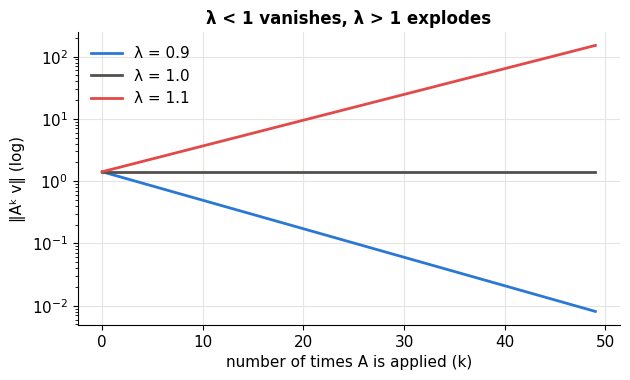

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.8))
v0 = np.array([1.0, 1.0])
for lam_val, col in [(0.9, C["blue"]), (1.0, C["muted"]), (1.1, C["red"])]:
    A_pow = lam_val * np.eye(2)
    norms = [np.linalg.norm(np.linalg.matrix_power(A_pow, k) @ v0) for k in range(50)]
    ax.plot(norms, color=col, label=f"λ = {lam_val}")
ax.set(yscale="log", xlabel="number of times A is applied (k)", ylabel="‖Aᵏ v‖ (log)",
       title="λ < 1 vanishes, λ > 1 explodes")
ax.legend(); plt.show()

### Power iteration: finding the biggest eigenvector without solving anything

Repeatedly multiplying by $A$ amplifies the direction with the largest $|\lambda|$ the most. So if you just keep applying $A$ (and re-normalizing), any starting vector swings toward the top eigenvector. This tiny algorithm powers Google's original **PageRank**, and it's one way to compute **PCA**.

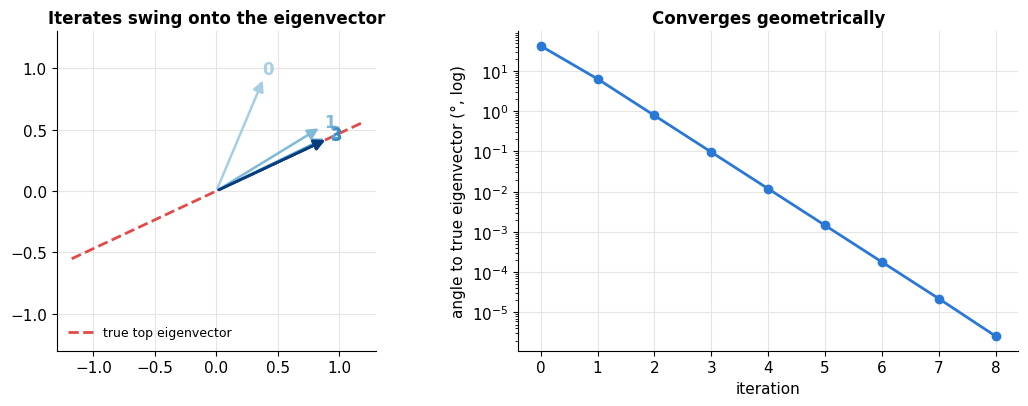

In [20]:
def power_iteration(A, steps=8, seed=1):
    v = np.random.default_rng(seed).normal(size=A.shape[0])
    vs = [v / np.linalg.norm(v)]
    for _ in range(steps):
        v = A @ v
        v = v / np.linalg.norm(v)          # re-normalize so it doesn't blow up
        vs.append(v)
    return np.array(vs)

A_pi = np.array([[3.0, 1.2], [1.2, 1.0]])
vs = power_iteration(A_pi)
top = np.linalg.eigh(A_pi)[1][:, -1]
errs = [np.degrees(np.arccos(min(1, abs(v @ top)))) for v in vs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(*np.outer([-1.3, 1.3], top).T, color=C["red"], ls="--", label="true top eigenvector")
for k, v in enumerate(vs[:7]):
    arrow(ax1, v, plt.cm.Blues(0.35 + 0.1 * k), f"{k}" if k < 4 else None, lw=1.8)
ax1.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", title="Iterates swing onto the eigenvector")
ax1.legend(loc="lower left", fontsize=9)
ax2.semilogy(errs, "o-", color=C["blue"])
ax2.set(xlabel="iteration", ylabel="angle to true eigenvector (°, log)", title="Converges geometrically")
fig.tight_layout(); plt.show()

> 🤔 **Question: How fast does power iteration converge?**
>
> The error shrinks by a factor of $|\lambda_2 / \lambda_1|$ each step (second-largest over largest eigenvalue). If the two are close, it's slow; if the top eigenvalue dominates, it's very fast. That's why the plot above is a straight line on a log scale.

---
## 9. Symmetric and positive semi-definite (PSD) matrices

For a symmetric matrix $A$, the **quadratic form** $f(x) = x^\top A x$ is a surface over the plane. Its shape is completely determined by the signs of the eigenvalues:

| Eigenvalues | Name | Shape of $x^\top A x$ |
|---|---|---|
| all $> 0$ | positive definite (PD) | a **bowl** with one lowest point |
| all $\ge 0$ | positive **semi**-definite (PSD) | a bowl or a flat-bottomed **trough** |
| mixed signs | indefinite | a **saddle** |
| all $< 0$ | negative definite | an upside-down bowl (a **dome**) |

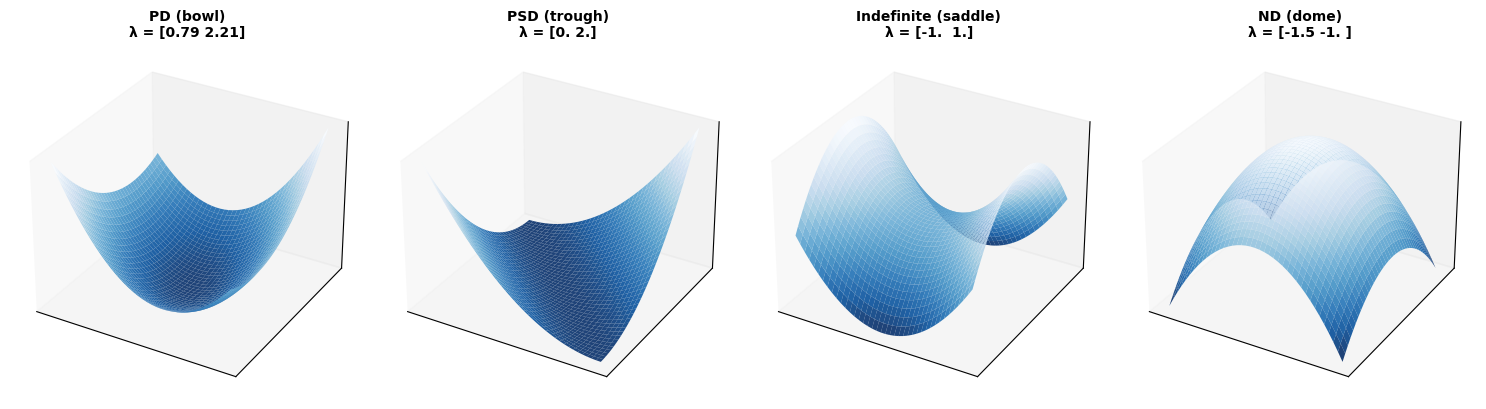

In [21]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3-D plots)

forms = {"PD (bowl)": [[2, 0.5], [0.5, 1]], "PSD (trough)": [[1, 1], [1, 1]],
         "Indefinite (saddle)": [[1, 0], [0, -1]], "ND (dome)": [[-1.5, 0], [0, -1]]}
g = np.linspace(-2, 2, 40); GX, GY = np.meshgrid(g, g)
fig = plt.figure(figsize=(15, 4))
for i, (name, A) in enumerate(forms.items()):
    A = np.array(A, float)
    Zq = A[0, 0] * GX**2 + (A[0, 1] + A[1, 0]) * GX * GY + A[1, 1] * GY**2
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.plot_surface(GX, GY, Zq, cmap="Blues_r", edgecolor="none", alpha=0.9)
    ax.set_title(f"{name}\nλ = {np.round(np.linalg.eigvalsh(A), 2)}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.tight_layout(); plt.show()

### Why the eigenvalues decide everything (CX 4240 HW1)

Write $A = \sum_i \lambda_i v_i v_i^\top$ (the eigendecomposition again). Then for any $x$:

$$x^\top A x = \sum_i \lambda_i\, x^\top v_i v_i^\top x = \sum_i \lambda_i (v_i^\top x)^2$$

Each $(v_i^\top x)^2 \ge 0$, so if every $\lambda_i \ge 0$ the whole sum is $\ge 0$: the matrix is PSD. If some $\lambda_i < 0$, pick $x = v_i$ and the form is negative. So **$A$ is PSD $\iff$ all eigenvalues $\ge 0$**. Let's verify the identity numerically:

In [22]:
A = np.array([[2, 0.5], [0.5, 1.0]]); lam, V = np.linalg.eigh(A)
x = rng.normal(size=2)
print(f"xᵀAx              = {x @ A @ x:.6f}")
print(f"Σ λᵢ (vᵢᵀx)²      = {np.sum(lam * (V.T @ x) ** 2):.6f}")

# Any matrix of the form XᵀX (like a covariance) is automatically PSD:
Xr = rng.normal(size=(100, 5))
print("\nEigenvalues of XᵀX (all ≥ 0):", np.round(np.linalg.eigvalsh(Xr.T @ Xr), 2))

xᵀAx              = 0.080714
Σ λᵢ (vᵢᵀx)²      = 0.080714

Eigenvalues of XᵀX (all ≥ 0): [ 66.49  81.25  92.12 104.93 121.03]


🎚️ **Morph a bowl into a saddle.** The matrix is $\begin{bmatrix}1 & b \\ b & 1\end{bmatrix}$, with eigenvalues $1+b$ and $1-b$. When $|b|$ crosses 1, one eigenvalue turns negative and the bowl splits into a saddle.

In [23]:
def plot_quadform(b=0.5):
    A = np.array([[1, b], [b, 1]])
    Zq = GX**2 + 2 * b * GX * GY + GY**2
    lam = np.linalg.eigvalsh(A)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    lim = np.abs(Zq).max()
    cs = ax.contourf(GX, GY, Zq, levels=np.linspace(-lim, lim, 25), cmap="RdBu_r")
    ax.contour(GX, GY, Zq, levels=[0], colors=C["ink"], linewidths=1.5)
    kind = "PD bowl" if lam.min() > 1e-9 else ("PSD trough" if lam.min() > -1e-9 else "indefinite saddle")
    ax.set(aspect="equal", title=f"λ = {lam.round(2)} → {kind}"); ax.grid(False)
    plt.colorbar(cs, ax=ax, label="xᵀAx"); plt.show()

interact(plot_quadform, b=FloatSlider(value=0.5, min=-1.5, max=1.5, step=0.05, description="b"));

> 🤔 **Question: Why should an ML person care about bowls vs. saddles?**
>
> Because near any point, a loss function looks like a quadratic form whose matrix is the **Hessian** (the matrix of second derivatives). PD Hessian means you're in a bowl (a local minimum). Indefinite means a saddle point, which is extremely common in neural networks and slows gradient descent down. Also, the loss of linear regression is a quadratic form with matrix $X^\top X$, which is always PSD, so the loss is always a bowl (convex) with no bad local minima. Notebook 03 builds on this.

---
## 10. The Singular Value Decomposition (SVD)

Eigendecomposition needs a square (and ideally symmetric) matrix. The **SVD works for every matrix**, any shape:

$$A = U \Sigma V^\top$$

- $V^\top$: a **rotation** (orthogonal), turning the input space,
- $\Sigma$: a **diagonal stretch** by the **singular values** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$,
- $U$: another **rotation** of the output space.

**Every matrix is rotate → stretch → rotate.** Geometrically, $A$ maps the unit circle to an **ellipse** whose axis lengths are the singular values.

### 🎬 The SVD, one step at a time

In [24]:
A_svd = np.array([[1.5, 1.0], [0.3, 1.2]])
U_, S_, Vt_ = np.linalg.svd(A_svd)
if np.linalg.det(U_) < 0:                          # make both U and V pure rotations (no reflections)
    U_[:, 1] *= -1; Vt_[1, :] *= -1
rot_angle = lambda R: np.arctan2(R[1, 0], R[0, 0])
R = lambda a: np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
aV, aU = rot_angle(Vt_), rot_angle(U_)

ts = np.linspace(0, 2 * np.pi, 200)
circ = np.column_stack([np.cos(ts), np.sin(ts)])
v1, v2 = Vt_[0], Vt_[1]                            # right singular vectors (rows of Vᵀ)

def stage_matrix(k, per=20):
    s, t = divmod(k, per); t = min(t / (per - 1), 1) if s < 3 else 1
    if s == 0: return R(aV * t), "1) Vᵀ: rotate"
    if s == 1: return np.diag([1 + t * (S_[0] - 1), 1 + t * (S_[1] - 1)]) @ R(aV), "2) Σ: stretch along the axes"
    return R(aU * t) @ np.diag(S_) @ R(aV), "3) U: rotate" if s == 2 else "result: A = U Σ Vᵀ"

fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=80)
def frame(k):
    M, label = stage_matrix(k)
    ax.cla()
    ax.plot(*circ.T, color=C["light"], ls="--", lw=1)
    E = circ @ M.T
    ax.fill(*E.T, color=C["blue"], alpha=0.2); ax.plot(*E.T, color=C["blue"])
    arrow(ax, M @ v1, C["red"], "v₁"); arrow(ax, M @ v2, C["aqua"], "v₂")
    ax.set(xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), aspect="equal", title=label); ax.grid(False)

print("singular values σ =", S_.round(3), "→ the ellipse's semi-axis lengths")
show_anim(animation.FuncAnimation(fig, frame, frames=70, interval=70))

singular values σ = [2.062 0.728] → the ellipse's semi-axis lengths


The red and aqua vectors are the **right singular vectors** $v_1, v_2$: the two perpendicular input directions that stay perpendicular after the transformation. They become the ellipse's axes, with lengths $\sigma_1$ and $\sigma_2$.

**Connection to eigenvalues:** $A^\top A = V\Sigma^\top U^\top U \Sigma V^\top = V \Sigma^2 V^\top$. So the right singular vectors are the eigenvectors of $A^\top A$, and $\sigma_i = \sqrt{\lambda_i(A^\top A)}$. This identity is how **PCA** is computed in practice (notebook 16).

In [25]:
print("σ from SVD           :", np.linalg.svd(A_svd, compute_uv=False).round(6))
print("√ eigenvalues of AᵀA :", np.sqrt(np.linalg.eigvalsh(A_svd.T @ A_svd))[::-1].round(6))

σ from SVD           : [2.061716 0.727549]
√ eigenvalues of AᵀA : [2.061716 0.727549]


---
## 11. Low-rank approximation: compressing an image with the SVD

Write the SVD as a **sum of rank-1 layers**:

$$A = \sum_{i=1}^{r} \sigma_i\, u_i v_i^\top$$

Each term $u_i v_i^\top$ is a simple "outer product" pattern, weighted by its singular value. Since the $\sigma_i$ are sorted from biggest to smallest, keeping only the first $k$ terms gives the **best possible rank-$k$ approximation** of $A$ (the **Eckart–Young theorem**). Let's apply that to a photo, which is just a matrix of pixel brightnesses.

Image: 427×640 = 273,280 numbers,  rank = 427


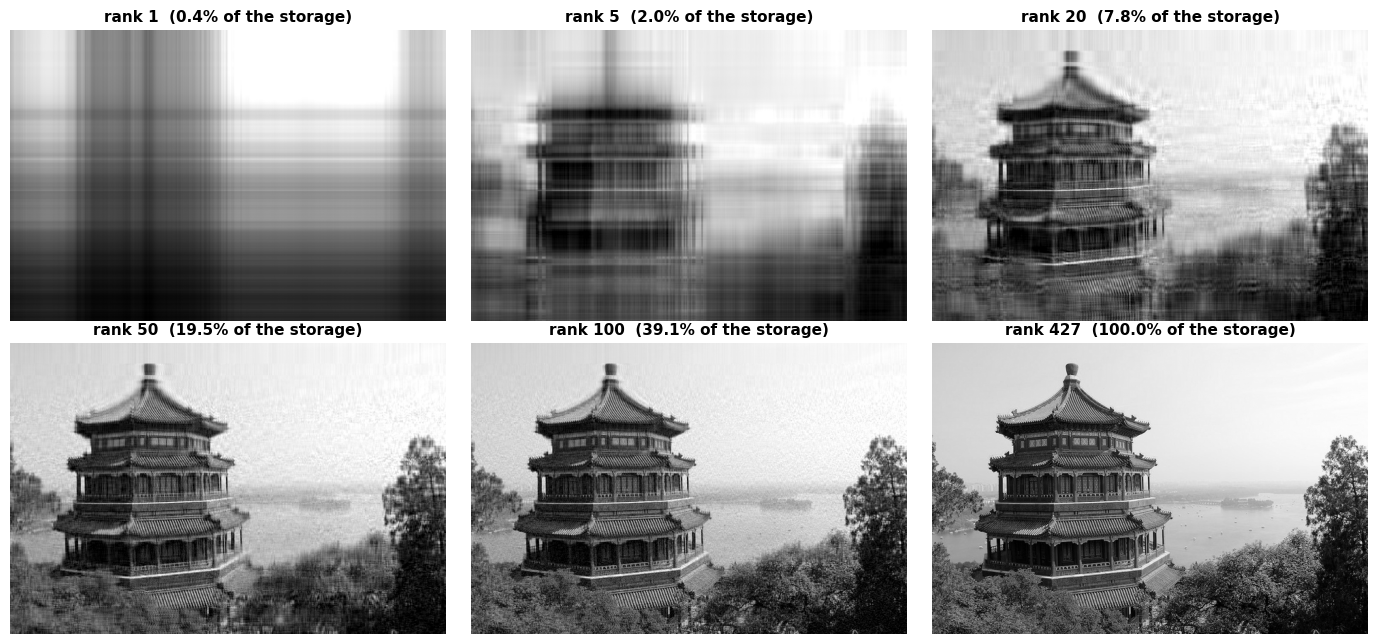

In [26]:
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg").mean(axis=2) / 255.0      # to grayscale, values in [0, 1]
m, n_cols = img.shape
U_i, S_i, Vt_i = np.linalg.svd(img, full_matrices=False)
print(f"Image: {m}×{n_cols} = {m*n_cols:,} numbers,  rank = {len(S_i)}")

def low_rank(k):
    return (U_i[:, :k] * S_i[:k]) @ Vt_i[:k]

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, k in zip(axes.flat, [1, 5, 20, 50, 100, len(S_i)]):
    ax.imshow(np.clip(low_rank(k), 0, 1), cmap="gray")
    store = k * (m + n_cols + 1) / (m * n_cols)
    ax.set_title(f"rank {k}  ({min(store, 1):.1%} of the storage)", fontsize=11); ax.axis("off")
fig.tight_layout(); plt.show()

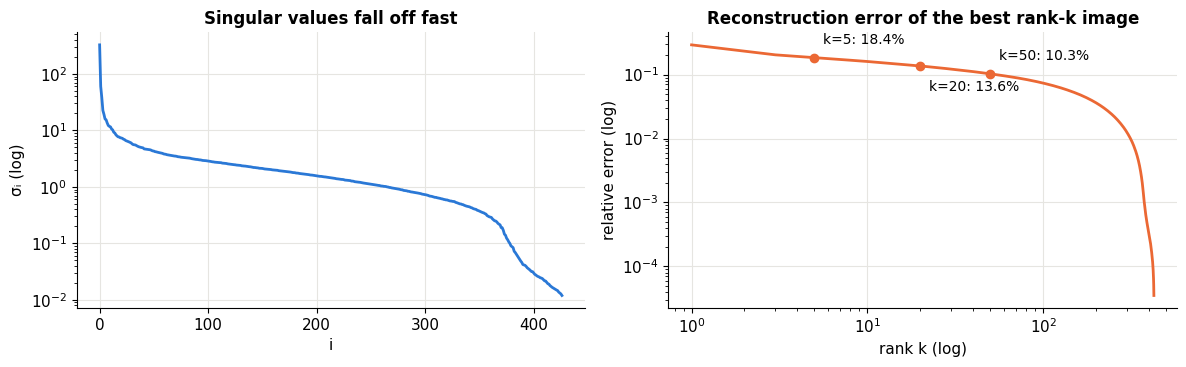

In [27]:
energy = np.cumsum(S_i**2) / np.sum(S_i**2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.semilogy(S_i, color=C["blue"]); ax1.set(xlabel="i", ylabel="σᵢ (log)", title="Singular values fall off fast")
rel_err = np.sqrt(np.clip(1 - energy, 0, None))     # ‖A − A_k‖ / ‖A‖ (Frobenius), from the discarded σ's
ks = np.arange(1, len(S_i) + 1)
ax2.loglog(ks[:-1], rel_err[:-1], color=C["orange"])
for k, yoff in [(5, 10), (20, -18), (50, 10)]:
    ax2.plot(k, rel_err[k - 1], "o", color=C["orange"])
    ax2.annotate(f"k={k}: {rel_err[k-1]:.1%}", (k, rel_err[k - 1]), xytext=(6, yoff), textcoords="offset points", fontsize=10)
ax2.set(xlabel="rank k (log)", ylabel="relative error (log)", title="Reconstruction error of the best rank-k image")
fig.tight_layout(); plt.show()

🎚️ **Choose the rank $k$.** Find the smallest $k$ where the image looks fine to you. Notice how little storage it needs.

In [28]:
def plot_rank(k=20):
    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.imshow(np.clip(low_rank(k), 0, 1), cmap="gray"); ax.axis("off")
    err = np.linalg.norm(img - low_rank(k)) / np.linalg.norm(img)
    ax.set_title(f"rank {k}: storage {k*(m+n_cols+1)/(m*n_cols):.1%}, relative error {err:.1%}")
    plt.show()

interact(plot_rank, k=IntSlider(value=20, min=1, max=200, step=1, continuous_update=False, description="rank k"));

> 🤔 **Question: Where does low-rank approximation show up in real ML?**
>
> All over the place:
> - **PCA** (16): keep the top-$k$ singular directions of the data matrix. The **eigenfaces** in ISYE 4600 HW2 are exactly the $v_i$'s of a matrix of face images.
> - **Recommender systems** (17): the Netflix rating matrix is assumed to be low-rank, because a few hidden "taste factors" explain most ratings.
> - **LoRA**: the standard way to fine-tune large language models only learns a low-rank update $W + BA$ with $B$ and $A$ thin matrices, saving ~99% of the trainable parameters.
> - **Compression** of neural network weights for phones.

---
## 12. Matrix calculus, and solving linear regression exactly

The **gradient** of a scalar function $f(\theta)$ with respect to a vector $\theta \in \mathbb{R}^d$ is the vector of partial derivatives:

$$\nabla_\theta f = \left(\frac{\partial f}{\partial \theta_1}, \dots, \frac{\partial f}{\partial \theta_d}\right)^\top$$

(Notebook 04 builds gradients from scratch; here we just need three rules.)

| Function $f(\theta)$ | Gradient $\nabla_\theta f$ | Scalar analogue |
|---|---|---|
| $a^\top \theta$ | $a$ | $\frac{d}{dx} ax = a$ |
| $\theta^\top A \theta$ | $(A + A^\top)\theta$ $= 2A\theta$ if $A$ symmetric | $\frac{d}{dx} ax^2 = 2ax$ |
| $\lVert X\theta - y \rVert^2$ | $2X^\top(X\theta - y)$ | $\frac{d}{dx}(ax - y)^2 = 2a(ax-y)$ |

### Deriving the normal equation

The least-squares loss expands into exactly the first two rules:

$$\|X\theta - y\|^2 = (X\theta - y)^\top(X\theta - y) = \theta^\top \underbrace{X^\top X}_{\text{symmetric}} \theta - 2 (X^\top y)^\top \theta + y^\top y$$

Taking the gradient term by term: $\nabla = 2X^\top X\theta - 2X^\top y$. At the minimum the gradient is zero:

$$X^\top X\,\theta^* = X^\top y \qquad \Longrightarrow \qquad \theta^* = (X^\top X)^{-1}X^\top y$$

These are the **normal equations**. ($X^\top X$ is PSD, so the loss is a bowl and this stationary point really is the minimum. And as section 7 showed, this only works if $X^\top X$ is invertible.)

> 📝 **Notation note:** CX 4240 Lecture 2 stacks data points as **columns** of $X$, so its formula reads $\hat\theta = (XX^\top)^{-1}Xy$. It's the same equation with $X$ transposed. This series uses the more common rows-as-examples convention.

Let's check the gradient formula numerically, then solve the apartment problem:

In [29]:
def numerical_grad(f, theta, h=1e-6):
    """Central-difference estimate of ∇f, one coordinate at a time."""
    g = np.zeros_like(theta)
    for i in range(len(theta)):
        e = np.zeros_like(theta); e[i] = h
        g[i] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g

Xa = rng.normal(size=(20, 3)); ya = rng.normal(size=20); th = rng.normal(size=3)
loss = lambda t: np.sum((Xa @ t - ya) ** 2)
print("analytic  2Xᵀ(Xθ−y):", (2 * Xa.T @ (Xa @ th - ya)).round(6))
print("numerical          :", numerical_grad(loss, th).round(6))

analytic  2Xᵀ(Xθ−y): [-1.099851 24.814126 -3.572936]
numerical          : [-1.099851 24.814126 -3.572936]


In [30]:
# The four apartments from CX 4240 Lecture 2: rent = θ0 + θ1·area + θ2·bedrooms
X_apt = np.column_stack([np.ones(4), apartments["area_ft2"], apartments["bedrooms"]])
y_apt = apartments["rent"].to_numpy(float)

theta_ne = np.linalg.solve(X_apt.T @ X_apt, X_apt.T @ y_apt)        # normal equation
theta_ls = np.linalg.lstsq(X_apt, y_apt, rcond=None)[0]              # the robust way
print("θ (normal equation):", theta_ne.round(3))
print("θ (lstsq)          :", theta_ls.round(3))
for a_, b_ in [(150, 1), (270, 1.5)]:
    print(f"  predicted rent for {a_} ft², {b_} bed: ${theta_ne @ [1, a_, b_]:,.0f}")

θ (normal equation): [ 235.027    3.738 -169.988]
θ (lstsq)          : [ 235.027    3.738 -169.988]
  predicted rent for 150 ft², 1 bed: $626
  predicted rent for 270 ft², 1.5 bed: $989


> 🤔 **Question: The bedroom coefficient might come out strange (even negative). Is that a bug?**
>
> No. With only 4 apartments and 3 parameters, the fit is nearly exact and the coefficients are very sensitive to each data point. Also, area and bedrooms are correlated (bigger places have more bedrooms), so the model can trade one off against the other. This is the "nearly singular $X^\top X$" problem from section 7 in a milder form, and it's a preview of **variance** in the bias–variance tradeoff (notebook 06).

---
## 13. Summary

| Concept | One-line intuition | Where it comes back |
|---|---|---|
| Vectors & norms | points/arrows; $\ell_1$ diamond vs $\ell_2$ circle | Lasso vs Ridge (07), distances in KNN (10), k-means (14) |
| Dot product | similarity / projection | cosine similarity (17), attention $QK^\top$ (25), SVM margins (11) |
| Matrix = transformation | columns are where the basis vectors land | every neural network layer (19) |
| Matrix multiplication | composition; a table of dot products | everything; GPUs |
| Determinant, rank, null space | volume scaling; squashing loses information | correlated features, Ridge (07) |
| Eigenvectors | directions that only stretch | PCA (16), PageRank, vanishing gradients (22) |
| PSD matrices | bowls; all eigenvalues ≥ 0 | covariances (02), convexity & Hessians (03), kernels in SVM (11) |
| SVD | every matrix = rotate → stretch → rotate | PCA (16), recommenders (17), LoRA |
| Normal equation | set gradient to 0: $X^\top X\theta = X^\top y$ | linear regression (05) |

### ✏️ Exercises

1. Find a 2×2 matrix (other than the identity) that is its own inverse, $A^2 = I$. What does it do geometrically? *(Hint: try the reflection.)*
2. Using `plot_eigen`, find a matrix with eigenvalues 2 and −1. What does the negative eigenvalue do to vectors along that direction?
3. Prove that if $Q$ is orthogonal then $\|Qx\| = \|x\|$. *(Hint: write $\|Qx\|^2 = (Qx)^\top(Qx)$.)*
4. Modify `power_iteration` to also return the eigenvalue estimate $v^\top A v$. Check it against `np.linalg.eigh`.
5. Compress the image with rank 30. What compression ratio do you get, and what's the relative error?
6. Add a column `area_m2 = 0.0929 * area` to the apartment matrix and try the normal equation. What happens? Then add `1e-3 * np.eye(4)` to $X^\top X$ (Ridge!). What happens now?

### References

- CX 4240 Lecture 2 (Linear Algebra Revisit) and HW1 Q1.
- ISYE 4600 HW2: correlated features, PCA and eigenfaces.
- 3Blue1Brown, *Essence of Linear Algebra* (YouTube): the "matrices move space" view.
- Zico Kolter, *Linear Algebra Review and Reference* (Stanford CS229), recommended in CX 4240.
- K. B. Petersen & M. S. Pedersen, *The Matrix Cookbook*, for every matrix-calculus identity.
- G. Strang, *Introduction to Linear Algebra*.

**Next → [02 · Probability & Statistics](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/02_probability_statistics.ipynb)**